In [1]:
import torch

x = torch.tensor([2.0, 4.0, 6.0])
y = torch.tensor([80.0, 140.0, 190.0])

assert x.dtype == torch.float32
assert y.dtype == torch.float32

w = 27.5
b = 26.67

y_hat = x * w + b
error = y - y_hat
mse = (error ** 2).mean()
assert abs(mse - 5.556) < 1e-3

print(mse)
print(mse.item())

tensor(5.5556)
5.555566787719727


In [2]:
import pandas as pd

train = pd.read_csv("../data/train_features.csv")
val = pd.read_csv("../data/val_features.csv")

X_train = train.drop(columns = ["price", "id"]).astype(float)
y_train = train["price"]
X_val = val.drop(columns = ["price", "id"]).astype(float)
y_val = val["price"]

X_train_std = (X_train - X_train.mean()) / X_train.std()
X_val_std = (X_val - X_train.mean()) / X_train.std()

X_tr_t = torch.tensor(X_train_std.to_numpy(), dtype = torch.float32)
y_tr_t = torch.tensor(y_train.to_numpy(), dtype = torch.float32).reshape(-1, 1)
X_va_t = torch.tensor(X_val_std.to_numpy(), dtype = torch.float32)
y_va_t = torch.tensor(y_val.to_numpy(), dtype = torch.float32).reshape(-1, 1)

assert X_tr_t.shape == (12747, 132)
assert y_tr_t.shape == (12747, 1)
assert X_va_t.shape == (2732, 132)
assert y_va_t.shape == (2732, 1)

assert X_tr_t.dtype == torch.float32
assert y_tr_t.dtype == torch.float32
assert X_va_t.dtype == torch.float32
assert y_va_t.dtype == torch.float32

assert max(abs(X_tr_t.mean(dim=0))) < 1e-4

In [3]:
from torch.utils.data import Dataset

class AirbnbDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        return (self.X[i], self.y[i])

train_ds = AirbnbDataset(X_tr_t, y_tr_t)
val_ds = AirbnbDataset(X_va_t, y_va_t)

assert len(train_ds) == 12747
assert len(val_ds) == 2732
assert train_ds[5][0].shape == (132,)
assert train_ds[3][1] == y_tr_t[3]
assert train_ds[len(train_ds) - 1][1] == y_tr_t[len(train_ds) - 1]
assert val_ds[8][1] == y_va_t[8]

In [4]:
# 64 * 199 + 11 = 12747 -> len(train_loader) = 200 and the last batch has 11 elements.

from torch.utils.data import DataLoader

train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)
assert len(train_loader) == 200
for xb, yb in train_loader:
    last = xb
assert len(last) == 11
for xb, yb in train_loader:
    assert xb.shape == (64, 132)
    assert yb.shape == (64, 1)
    break

In [5]:
pred = torch.tensor([[100.0], [150.0], [200.0]])   # como saldría de la red
y_toy = torch.tensor([80.0, 140.0, 190.0]).reshape(-1, 1)
assert (pred - y_toy).shape == (3, 1)
assert abs(((pred - y_toy) ** 2).mean().item() - 200) <= 1e-6

In [6]:
from torch import nn
layer = nn.Linear(132, 1)
assert layer.weight.shape == (1, 132)
assert layer.bias.shape == (1,)
for xb, yb in train_loader:
    assert layer(xb).shape == (64, 1)
    break

In [7]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(132, 16)
        self.out = nn.Linear(16, 1)
    def forward(self, x):
        h = torch.relu(self.hidden(x))
        return self.out(h)

model = MLP()
assert model(xb).shape == (64, 1)
assert sum(p.numel() for p in model.parameters()) == 132 * 16 + 16 + 16 * 1 + 1


loss_fn = nn.MSELoss()
for xb, yb in train_loader:
    loss = loss_fn(model(xb), yb)
    print(loss.item())
    loss.backward()
    assert model.hidden.weight.grad.shape == (16, 132)
    assert model.out.bias.grad.shape == (1,)
    break

loss = loss_fn(model(X_tr_t),y_tr_t)
print(loss.item())


45844.859375
47653.59375


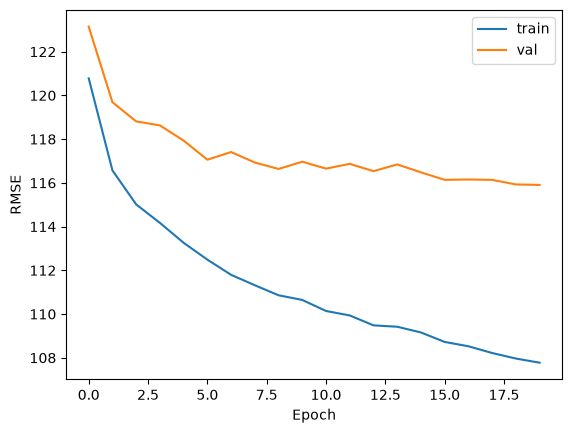

In [8]:
import matplotlib.pyplot as plt

rmses_tr = []
rmses_va = []

model = MLP()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_fn = nn.MSELoss()
for _ in range(20):
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
    with torch.no_grad():
        rmses_tr.append((((model(X_tr_t) - y_tr_t) ** 2).mean() ** 0.5).item())
        rmses_va.append((((model(X_va_t) - y_va_t) ** 2).mean() ** 0.5).item())

plt.plot(rmses_tr, label="train")
plt.plot(rmses_va, label="val")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()
plt.show()

In [9]:
best = min(rmses_va)
print(f"train final: {rmses_tr[-1]:.2f}, val final: {rmses_va[-1]:.2f}")
print(f"best val: {best:.2f} at epoch {rmses_va.index(best)}")
print(f"T4 linear val: 121.26")

train final: 107.77, val final: 115.90
best val: 115.90 at epoch 19
T4 linear val: 121.26


## MLP vs linear regression (T4)

| Model | Train RMSE | Val RMSE |
| --- | --- | --- |
| Linear regression (T4, gradient descent) | 117.4 | 121.26 |
| MLP 132-16-1, ReLU, Adam (lr = 0.01), 20 epochs | 107.5 | 116.4 |

- The MLP is about 5 € (4 %) better on validation.
- Both models are evaluated on the same 2,732 validation listings, so the fold-to-fold variation seen in T5 (± 8.8 €) does not apply: that variation came from changing the listings. The run-to-run variation of the MLP (random initial weights and batch order) was about 0.5 € in two runs, so the improvement is real, though modest.
- The loss curve shows the start of overfitting: train RMSE keeps falling (119.6 → 107.5) while validation RMSE is almost flat after epoch 3 (around 116-118).